In [2]:
#libraries import
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sqlite3

In [3]:
# import data
df = pd.read_csv(r"amazon.csv")
print(df.shape)
print(df.head())

(1465, 16)
   product_id                                       product_name  \
0  B07JW9H4J1  Wayona Nylon Braided USB to Lightning Fast Cha...   
1  B098NS6PVG  Ambrane Unbreakable 60W / 3A Fast Charging 1.5...   
2  B096MSW6CT  Sounce Fast Phone Charging Cable & Data Sync U...   
3  B08HDJ86NZ  boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...   
4  B08CF3B7N1  Portronics Konnect L 1.2M Fast Charging 3A 8 P...   

                                            category discounted_price  \
0  Computers&Accessories|Accessories&Peripherals|...             ₹399   
1  Computers&Accessories|Accessories&Peripherals|...             ₹199   
2  Computers&Accessories|Accessories&Peripherals|...             ₹199   
3  Computers&Accessories|Accessories&Peripherals|...             ₹329   
4  Computers&Accessories|Accessories&Peripherals|...             ₹154   

  actual_price discount_percentage rating rating_count  \
0       ₹1,099                 64%    4.2       24,269   
1         ₹349           

In [4]:
#columnsa and data types check
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   product_id           1465 non-null   str  
 1   product_name         1465 non-null   str  
 2   category             1465 non-null   str  
 3   discounted_price     1465 non-null   str  
 4   actual_price         1465 non-null   str  
 5   discount_percentage  1465 non-null   str  
 6   rating               1465 non-null   str  
 7   rating_count         1463 non-null   str  
 8   about_product        1465 non-null   str  
 9   user_id              1465 non-null   str  
 10  user_name            1465 non-null   str  
 11  review_id            1465 non-null   str  
 12  review_title         1465 non-null   str  
 13  review_content       1465 non-null   str  
 14  img_link             1465 non-null   str  
 15  product_link         1465 non-null   str  
dtypes: str(16)
memory usage: 183.3 KB


In [6]:
#check missing value
print(df.isnull().sum())

product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           2
about_product          0
user_id                0
user_name              0
review_id              0
review_title           0
review_content         0
img_link               0
product_link           0
dtype: int64


In [8]:
#calculate missing value percentage for each columns
print((df.isnull().sum()/len(df))*100)

product_id             0.000000
product_name           0.000000
category               0.000000
discounted_price       0.000000
actual_price           0.000000
discount_percentage    0.000000
rating                 0.000000
rating_count           0.136519
about_product          0.000000
user_id                0.000000
user_name              0.000000
review_id              0.000000
review_title           0.000000
review_content         0.000000
img_link               0.000000
product_link           0.000000
dtype: float64


In [9]:
#duplicate check
print("Duplicate rows: " , df.duplicated().sum())

Duplicate rows:  0


In [11]:
print("Duplicate product id: ", df["product_id"].duplicated().sum())

Duplicate product id:  114


In [12]:
# display all records with repeated product ids
duplicates = df[df["product_id"].duplicated(keep = False)]
display(duplicates)

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1007,B0B9BXKBC7,"WeCool S5 Long Selfie Stick, with Large Reinfo...",Electronics|Mobiles&Accessories|MobileAccessor...,"₹1,799","₹3,999",55%,4.6,245,"64"" Tall Cell Phone Tripods with 7 section adj...","AFPYH3UF3GB4RNX3MX46AXFM2FTQ,AGWEQHJSUA4YCG44R...","Sujili v,Paras Jain,Shailendra,supreeth achar,...","R2MI4KSWYUEMDR,R2MNYKDL2UII1M,R2C6TUBM6IVLB0,R...","Good,Good Product but Little expensive.,Happy ...","Good,Thoda sa kam stable hai, phone lagane ke ...",https://m.media-amazon.com/images/I/41fDM4QUfv...,https://www.amazon.in/WeCool-Reinforced-Functi...
1010,B07GVGTSLN,Wayona Usb Type C Fast Charger Cable Fast Char...,Computers&Accessories|Accessories&Peripherals|...,₹325,"₹1,299",75%,4.2,"10,576",Fast Charge & Data Sync: Fast charge& data tra...,"AEXK37TSBFHSP2TYE63YPKETWQ7Q,AEKMVX2VDNNX4ZFXI...","Sunil Funde,Biju Abraham Thomas,Samir,Rahul Sh...","R10365HEDURWI9,R5RP542IMC4OI,RX2HFWXTTQDTS,R26...","Nice product .,Good quality Braided cable, VFM...","Sturdy packing

In [14]:
# convert discounted_price to numeric
df["discounted_price"] = (
    df["discounted_price"]
    .str.replace("₹", "", regex = False)
    .str.replace(",", "", regex = False)
    .astype(float)
)

# convert actual_price to numeric
df["actual_price"] =(
    df["actual_price"]
    .str.replace("₹", "", regex = False)
    .str.replace(",", "", regex = False)
    .astype(float)
)

#convert discount_percenatge to numeric
df["discount_percentage"]= (
    df["discount_percentage"]
    .str.replace("%", "", regex = False)
    .astype(float)
)

#convert rating to numeric
df["rating"] = pd.to_numeric(df["rating_count"], errors = "coerce")

# convert rating_count to numeric
df["rating_count"] = pd.to_numeric(
    df["rating_count"].str.replace(",", "", regex = False),
    errors = "coerce"
)
                                   

In [16]:
print(df.dtypes)

product_id                 str
product_name               str
category                   str
discounted_price       float64
actual_price           float64
discount_percentage    float64
rating                 float64
rating_count           float64
about_product              str
user_id                    str
user_name                  str
review_id                  str
review_title               str
review_content             str
img_link                   str
product_link               str
dtype: object


In [17]:
# missing rows where rating_count is missing
missing_ratings = df[df["rating_count"].isnull()]
display(missing_ratings)

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
282,B0B94JPY2N,Amazon Brand - Solimo 65W Fast Charging Braide...,Computers&Accessories|Accessories&Peripherals|...,199.0,999.0,80.0,NaN,NaN,USB C to C Cable: This cable has type C connec...,AE7CFHY23VAJT2FI4NZKKP6GS2UQ,Pranav,RUB7U91HVZ30,The cable works but is not 65W as advertised,I have a pd supported car charger and I bought...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Amazon-Brand-Charging-Su...
324,B0BQRJ3C47,"REDTECH USB-C to Lightning Cable 3.3FT, [Apple...",Computers&Accessories|Accessories&Peripherals|...,249.0,999.0,75.0,NaN,NaN,💎[The Fastest Charge] - This iPhone USB C cabl...,AGJC5O5H5BBXWUV7WRIEIOOR3TVQ,Abdul Gafur,RQXD5SAMMPC6L,Awesome Product,Quick delivery.Awesome ProductPacking was good...,https://m.media-amazon.com/images/I/31-q0xhaTA...,https://www.amazon.in/REDTECH-Lightning-Certif...


In [22]:
#verify the actual values in the affected rows
display(
    df.loc[[282,324],[
        "product_id",
        "product_name",
        "about_product",
        "rating_count",
        "review_content"
    ]]
)

,product_id,product_name,about_product,rating_count,review_content
282,B0B94JPY2N,Amazon Brand - Solimo 65W Fast Charging Braide...,USB C to C Cable: This cable has type C connec...,NaN,I have a pd supported car charger and I bought...
324,B0BQRJ3C47,"REDTECH USB-C to Lightning Cable 3.3FT, [Apple...",💎[The Fastest Charge] - This iPhone USB C cabl...,NaN,Quick delivery.Awesome ProductPacking was good...


In [23]:
# Check leading and trailing spaces in text columns
text_columns = df.select_dtypes(include=["str"]).columns

for col in text_columns:
    count = df[col].dropna().ne(df[col].dropna().str.strip()).sum()
    print(f"{col}: {count} values with extra spaces")

product_id: 0 values with extra spaces
product_name: 0 values with extra spaces
category: 0 values with extra spaces
about_product: 0 values with extra spaces
user_id: 0 values with extra spaces
user_name: 0 values with extra spaces
review_id: 0 values with extra spaces
review_title: 0 values with extra spaces
review_content: 0 values with extra spaces
img_link: 0 values with extra spaces
product_link: 0 values with extra spaces


In [25]:
# check invalid discount percentage
print("Invalid discount percentages: ",
     (df["discount_percentage"].between(0,100)).sum())
# check rating outside the expected range
print("Invalid rating: ",
     (df["rating"].between(0,5)).sum())

#check negative discounted prices
print("Negative Prices: ",
     (df["discounted_price"]<0).sum())

#check negative actual prices
print("Negative actual values:",
     (df["actual_price"]<0).sum())

#check negative rating counts
print("Negative rating counts: ",
     (df["rating_count"]<0).sum())

Invalid discount percentages:  1465
Invalid rating:  6
Negative Prices:  0
Negative actual values: 0
Negative rating counts:  0


In [26]:
print(df["discount_percentage"].describe())

print("Minimum:", df["discount_percentage"].min())
print("Maximum:", df["discount_percentage"].max())

print(
    df.loc[
        ~df["discount_percentage"].between(0, 100),
        "discount_percentage"
    ].head(10)
)

count    1465.000000
mean       47.691468
std        21.635905
min         0.000000
25%        32.000000
50%        50.000000
75%        63.000000
max        94.000000
Name: discount_percentage, dtype: float64
Minimum: 0.0
Maximum: 94.0
Series([], Name: discount_percentage, dtype: float64)


In [27]:
display(
    df.loc[
        ~df["rating"].between(0, 5),
        ["product_id", "product_name", "rating"]
    ]
)

,product_id,product_name,rating
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,NaN
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,NaN
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,NaN
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,NaN
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,NaN
...,...,...,...
1460,B08L7J3T31,Noir Aqua - 5pcs PP Spun Filter + 1 Spanner | ...,NaN
1461,B01M6453MB,Prestige Delight PRWO Electric Rice Cooker (1 ...,NaN
1462,B009P2LIL4,Bajaj Majesty RX10 2000 Watts Heat Convector R...,468.0
1463,B00J5DYCCA,Havells Ventil Air DSP 230mm Exhaust Fan (Pist...,NaN


In [28]:
# Count missing ratings
print("Missing ratings:", df["rating"].isna().sum())

# Display only non-missing ratings outside the valid range
invalid_ratings = df[
    df["rating"].notna() &
    ~df["rating"].between(0, 5)
]

print("Invalid ratings:", len(invalid_ratings))

display(
    invalid_ratings[
        ["product_id", "product_name", "rating"]
    ]
)

Missing ratings: 1139
Invalid ratings: 320


,product_id,product_name,rating
20,B09C6HXFC1,Duracell USB Lightning Apple Certified (Mfi) B...,815.0
28,B09W5XR9RT,Duracell USB C To Lightning Apple Certified (M...,184.0
32,B08QSC1XY8,Zoul USB C 60W Fast Charging 3A 6ft/2M Long Ty...,974.0
33,B008FWZGSG,Samsung Original Type C to C Cable - 3.28 Feet...,355.0
37,B09RZS1NQT,"Sounce 65W OnePlus Dash Warp Charge Cable, 6.5...",576.0
...,...,...,...
1452,B0B8CB7MHW,KNOWZA Electric Handheld Milk Wand Mixer Froth...,222.0
1453,B07K19NYZ8,Usha Hc 812 T Thermo Fan Room Heater,195.0
1456,B0B9JZW1SQ,"4 in 1 Handheld Electric Vegetable Cutter Set,...",113.0
1458,B07J9KXQCC,"Libra Room Heater for Home, Room Heaters Home ...",550.0


In [29]:
# load the original dataset separately
df_original = pd.read_csv("amazon.csv")

#display original rating values
print(df_original["rating"].head(10))

#check original rating data type
print(df_original["rating"].dtype)

#check unique rating values
print(df_original["rating"].unique()[:20])

0    4.2
1    4.0
2    3.9
3    4.2
4    4.2
5    3.9
6    4.1
7    4.3
8    4.2
9    4.0
Name: rating, dtype: str
str
<StringArray>
['4.2', '4.0', '3.9', '4.1', '4.3', '4.4', '4.5', '3.7', '3.3', '3.6', '3.4',
 '3.8', '3.5', '4.6', '3.2', '5.0', '4.7', '3.0', '2.8',   '4']
Length: 20, dtype: str


In [30]:
# Restore the original rating values
df["rating"] = pd.to_numeric(
    df_original["rating"],
    errors="coerce"
)

# Verify the rating column
print("Data type:", df["rating"].dtype)
print("Missing ratings:", df["rating"].isna().sum())
print("Minimum rating:", df["rating"].min())
print("Maximum rating:", df["rating"].max())

# Check invalid ratings
print(
    "Invalid ratings:",
    df.loc[
        df["rating"].notna() &
        ~df["rating"].between(0, 5)
    ].shape[0]
)

Data type: float64
Missing ratings: 1
Minimum rating: 2.0
Maximum rating: 5.0
Invalid ratings: 0


In [31]:

# 1. Check dataset dimensions
print("Dataset shape:", df.shape)

# 2. Check data types
print("\nData types:")
print(df.dtypes)

# 3. Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# 4. Check completely duplicated rows
print("\nDuplicate rows:", df.duplicated().sum())

# 5. Check invalid ratings
print("\nInvalid ratings:",
      (df["rating"].notna() &
       ~df["rating"].between(0, 5)).sum())

# 6. Check invalid discount percentages
print("\nInvalid discount percentages:",
      (df["discount_percentage"].notna() &
       ~df["discount_percentage"].between(0, 100)).sum())

# 7. Check negative prices
print("\nNegative discounted prices:",
      (df["discounted_price"] < 0).sum())

print("Negative actual prices:",
      (df["actual_price"] < 0).sum())

# 8. Check discounted prices greater than actual prices
print("\nDiscounted price greater than actual price:",
      (df["discounted_price"] > df["actual_price"]).sum())


Dataset shape: (1465, 16)

Data types:
product_id                 str
product_name               str
category                   str
discounted_price       float64
actual_price           float64
discount_percentage    float64
rating                 float64
rating_count           float64
about_product              str
user_id                    str
user_name                  str
review_id                  str
review_title               str
review_content             str
img_link                   str
product_link               str
dtype: object

Missing values:
product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 1
rating_count           2
about_product          0
user_id                0
user_name              0
review_id              0
review_title           0
review_content         0
img_link               0
product_link           0
dtype: int64

Duplicate rows: 0

I

In [32]:
# Save the cleaned dataset
df.to_csv("amazon_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [33]:
# Check total rows and columns
print("Dataset Shape:", df.shape)

# Count unique products
print("Unique Products:", df["product_id"].nunique())

# Count unique product names
print("Unique Product Names:", df["product_name"].nunique())

Dataset Shape: (1465, 16)
Unique Products: 1351
Unique Product Names: 1337


In [34]:
# Count unique categories
print("Unique Categories:", df["category"].nunique())

# Count products by category
display(df["category"].value_counts().head(10))

Unique Categories: 211


category
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables                        233
Electronics|WearableTechnology|SmartWatches                                                               76
Electronics|Mobiles&Accessories|Smartphones&BasicMobiles|Smartphones                                      68
Electronics|HomeTheater,TV&Video|Televisions|SmartTelevisions                                             63
Electronics|Headphones,Earbuds&Accessories|Headphones|In-Ear                                              52
Electronics|HomeTheater,TV&Video|Accessories|RemoteControls                                               49
Home&Kitchen|Kitchen&HomeAppliances|SmallKitchenAppliances|MixerGrinders                                  27
Electronics|HomeTheater,TV&Video|Accessories|Cables|HDMICables                                            24
Computers&Accessories|Accessories&Peripherals|Keyboards,Mice&InputDevices|Mice                            24
Home&Kitch

In [35]:
# Calculate summary metrics
print("Average Discounted Price:", df["discounted_price"].mean())
print("Average Actual Price:", df["actual_price"].mean())
print("Average Discount Percentage:", df["discount_percentage"].mean())
print("Average Rating:", df["rating"].mean())
print("Average Rating Count:", df["rating_count"].mean())

Average Discounted Price: 3125.3108737201364
Average Actual Price: 5444.990634812287
Average Discount Percentage: 47.69146757679181
Average Rating: 4.096584699453552
Average Rating Count: 18295.541353383458


In [36]:
# Display the 10 highest-rated products
top_rated = df.sort_values(
    by="rating",
    ascending=False
)

display(
    top_rated[
        ["product_name", "rating", "rating_count", "discounted_price"]
    ].head(10)
)

,product_name,rating,rating_count,discounted_price
174,Syncwire LTG to USB Cable for Fast Charging Co...,5.0,5.0,399.0
324,"REDTECH USB-C to Lightning Cable 3.3FT, [Apple...",5.0,NaN,249.0
775,Amazon Basics Wireless Mouse | 2.4 GHz Connect...,5.0,23.0,499.0
1299,"Instant Pot Air Fryer, Vortex 2QT, Touch Contr...",4.8,3964.0,4995.0
1201,"Oratech Coffee Frother electric, milk frother ...",4.8,28.0,279.0
1145,Swiffer Instant Electric Water Heater Faucet T...,4.8,53803.0,1439.0
1223,"FIGMENT Handheld Milk Frother Rechargeable, 3-...",4.7,1729.0,699.0
1226,Zuvexa USB Rechargeable Electric Foam Maker - ...,4.7,54.0,499.0
1275,Multifunctional 2 in 1 Electric Egg Boiling St...,4.7,2300.0,699.0
459,Spigen EZ Fit Tempered Glass Screen Protector ...,4.7,7779.0,999.0


In [37]:
# Display the 10 products with the highest discount percentages
top_discounted = df.sort_values(
    by="discount_percentage",
    ascending=False
)

display(
    top_discounted[
        ["product_name", "discount_percentage",
         "actual_price", "discounted_price"]
    ].head(10)
)

,product_name,discount_percentage,actual_price,discounted_price
695,"rts [2 Pack] Mini USB C Type C Adapter Plug, T...",94.0,4999.0,294.0
372,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",91.0,19999.0,1799.0
380,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",91.0,19999.0,1799.0
364,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",91.0,19999.0,1799.0
368,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",91.0,19999.0,1799.0
334,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",91.0,19999.0,1799.0
557,LAPSTER 12pcs Spiral Cable Protectors for Char...,90.0,999.0,99.0
920,"Silicone Rubber Earbuds Tips, Eartips, Earpads...",90.0,999.0,99.0
644,Sounce Spiral Charger Cable Protector Data Cab...,90.0,999.0,99.0
407,Sounce Spiral Charger Cable Protector Data Cab...,90.0,999.0,99.0


In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           1465 non-null   str    
 1   product_name         1465 non-null   str    
 2   category             1465 non-null   str    
 3   discounted_price     1465 non-null   float64
 4   actual_price         1465 non-null   float64
 5   discount_percentage  1465 non-null   float64
 6   rating               1464 non-null   float64
 7   rating_count         1463 non-null   float64
 8   about_product        1465 non-null   str    
 9   user_id              1465 non-null   str    
 10  user_name            1465 non-null   str    
 11  review_id            1465 non-null   str    
 12  review_title         1465 non-null   str    
 13  review_content       1465 non-null   str    
 14  img_link             1465 non-null   str    
 15  product_link         1465 non-null   str    
dtyp

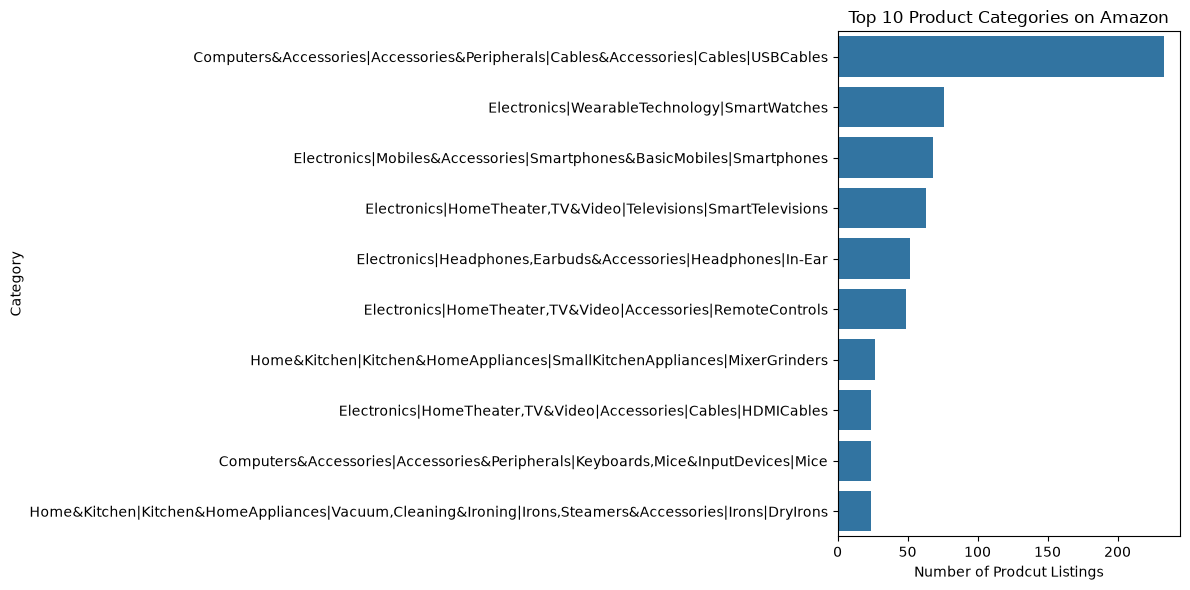

In [40]:
# find the top 10 categories
top_categories = df["category"].value_counts().head(10)

#create the bar chart
plt.figure(figsize = (12, 6))
sns.barplot(x= top_categories.values, y=top_categories.index)

# add chart title and label
plt.title("Top 10 Product Categories on Amazon")
plt.xlabel("Number of Prodcut Listings")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

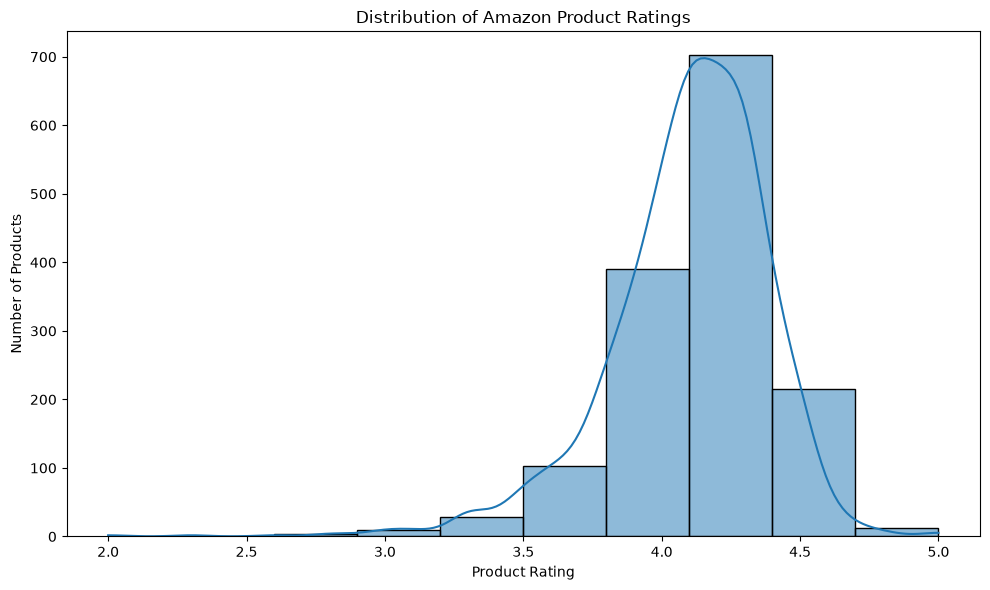

In [41]:
# Create a histogram of product ratings
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x="rating", bins=10, kde=True)

# Add chart title and labels
plt.title("Distribution of Amazon Product Ratings")
plt.xlabel("Product Rating")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()

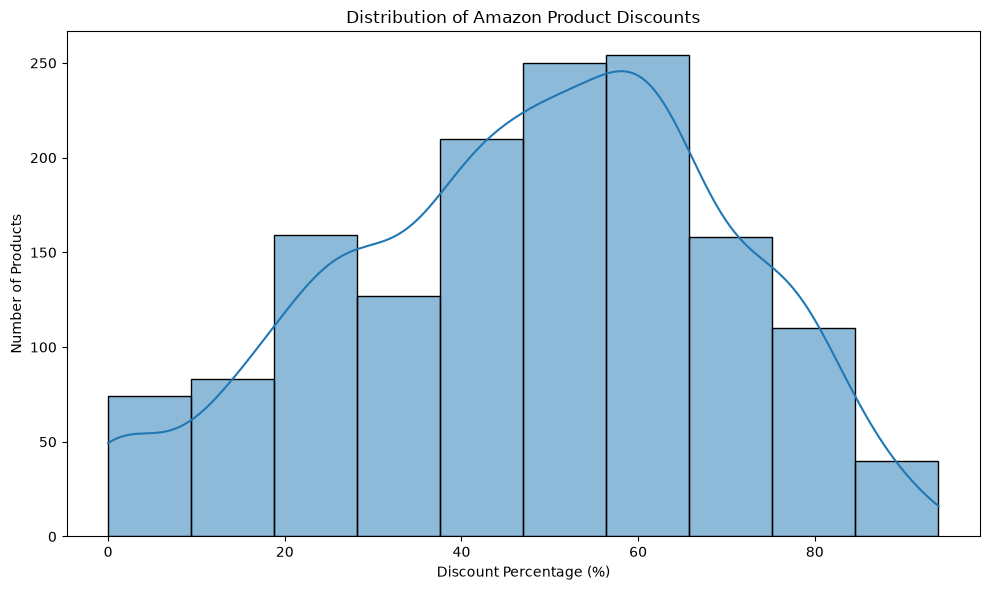

In [42]:
# Create a histogram of discount percentages
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x="discount_percentage", bins=10, kde=True)

# Add chart title and labels
plt.title("Distribution of Amazon Product Discounts")
plt.xlabel("Discount Percentage (%)")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()

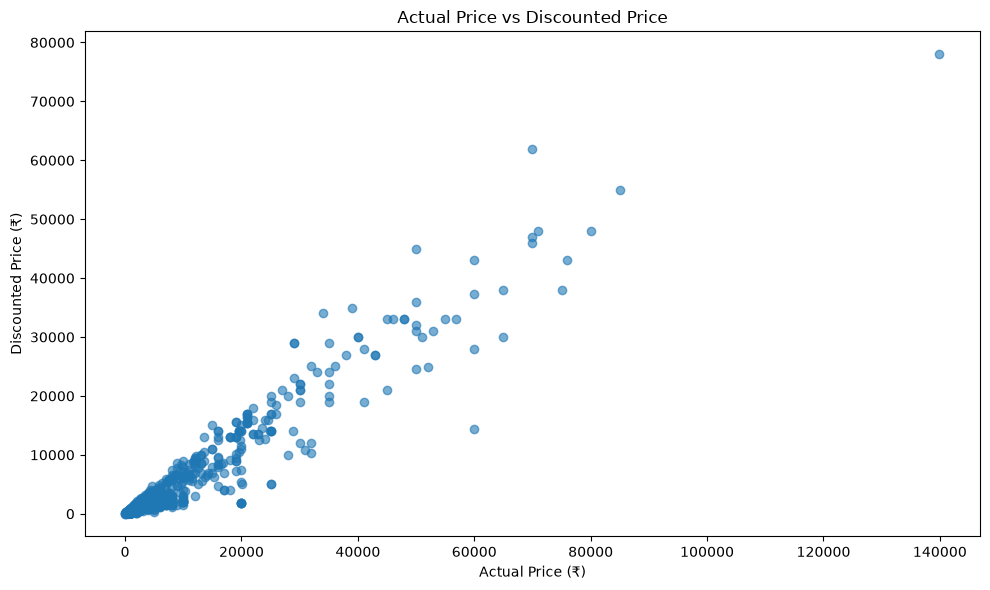

In [43]:
# Compare actual price and discounted price
plt.figure(figsize=(10, 6))

plt.scatter(df["actual_price"], df["discounted_price"], alpha=0.6)

# Add chart title and labels
plt.title("Actual Price vs Discounted Price")
plt.xlabel("Actual Price (₹)")
plt.ylabel("Discounted Price (₹)")

plt.tight_layout()
plt.show()

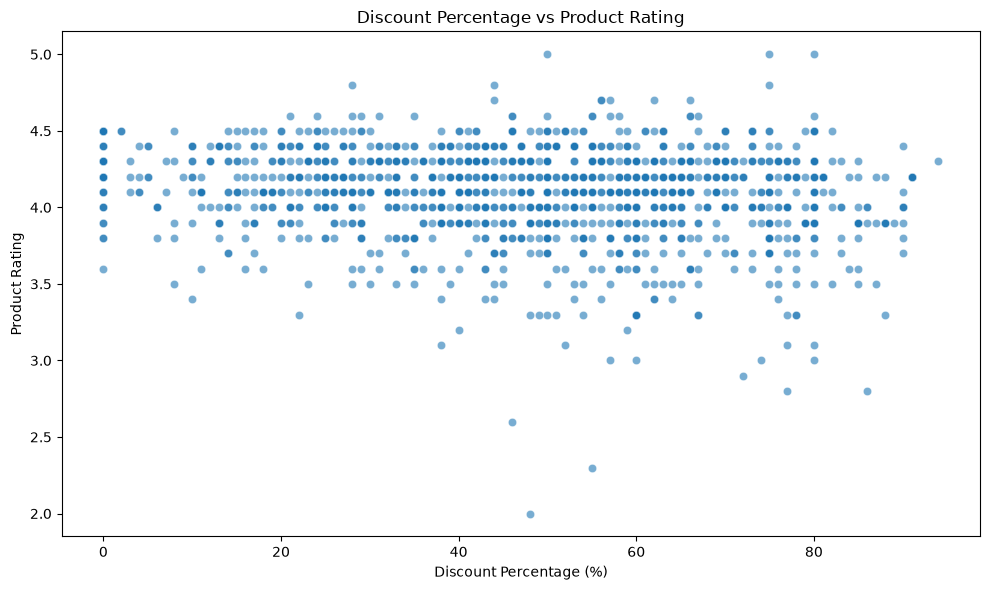

In [44]:
# Compare discount percentage with product rating
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="discount_percentage",
    y="rating",
    alpha=0.6
)

# Add chart title and labels
plt.title("Discount Percentage vs Product Rating")
plt.xlabel("Discount Percentage (%)")
plt.ylabel("Product Rating")

plt.tight_layout()
plt.show()

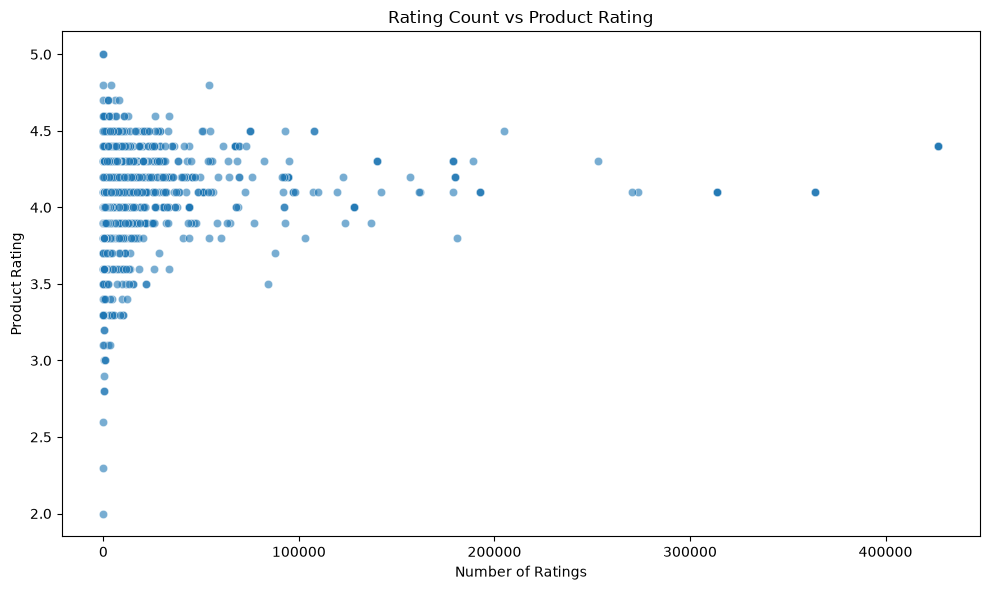

In [45]:
# Compare rating count with product rating
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="rating_count",
    y="rating",
    alpha=0.6
)

# Add chart title and labels
plt.title("Rating Count vs Product Rating")
plt.xlabel("Number of Ratings")
plt.ylabel("Product Rating")

plt.tight_layout()
plt.show()

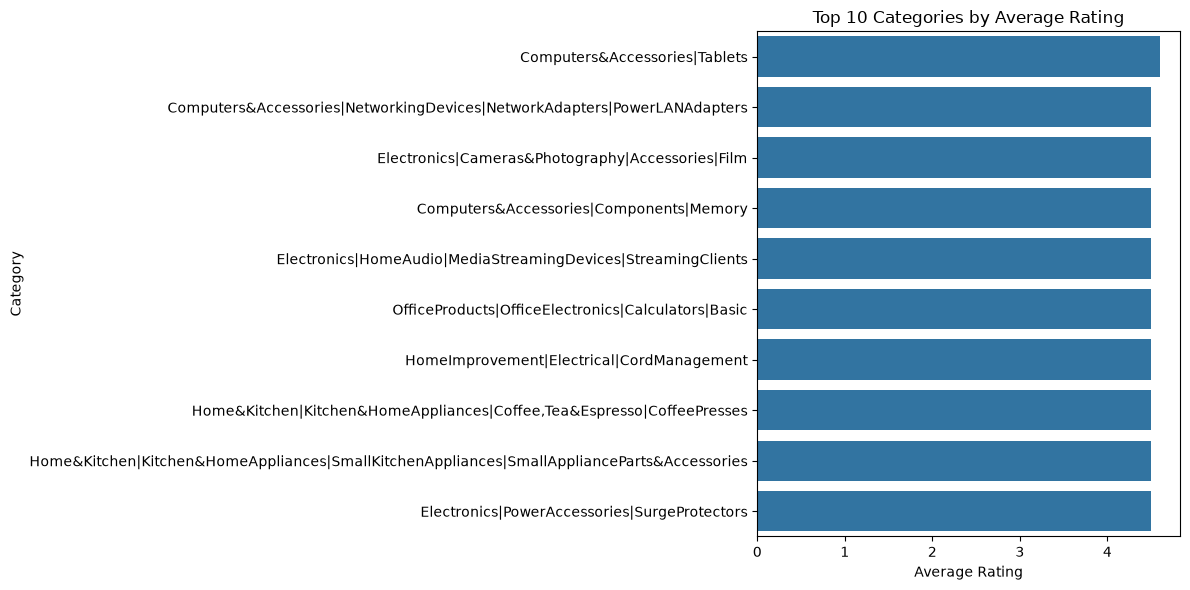

In [46]:
# Calculate average rating for each category
category_rating = (
    df.groupby("category")["rating"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

# Create the bar chart
plt.figure(figsize=(12, 6))
sns.barplot(x=category_rating.values, y=category_rating.index)

# Add chart title and labels
plt.title("Top 10 Categories by Average Rating")
plt.xlabel("Average Rating")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

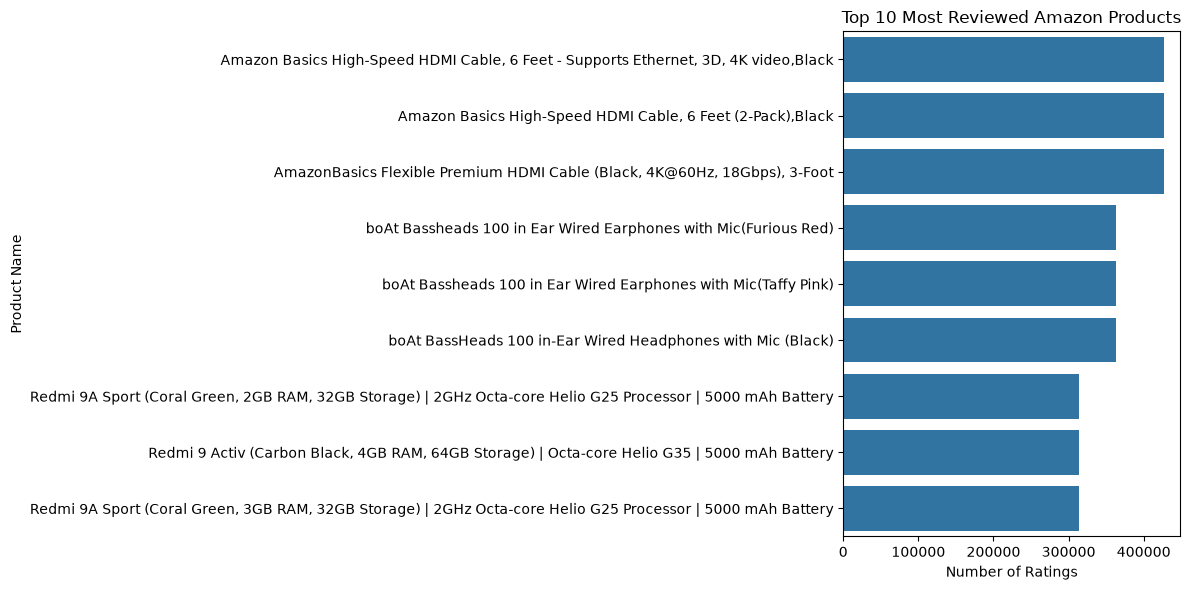

In [47]:
# Find the top 10 most reviewed products
top_reviewed = (
    df.sort_values(by="rating_count", ascending=False)
    .head(10)
)

# Create the bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_reviewed,
    x="rating_count",
    y="product_name"
)

# Add chart title and labels
plt.title("Top 10 Most Reviewed Amazon Products")
plt.xlabel("Number of Ratings")
plt.ylabel("Product Name")

plt.tight_layout()
plt.show()

C:\Users\asus\AppData\Local\Temp\ipykernel_23432\3763579417.py:21: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


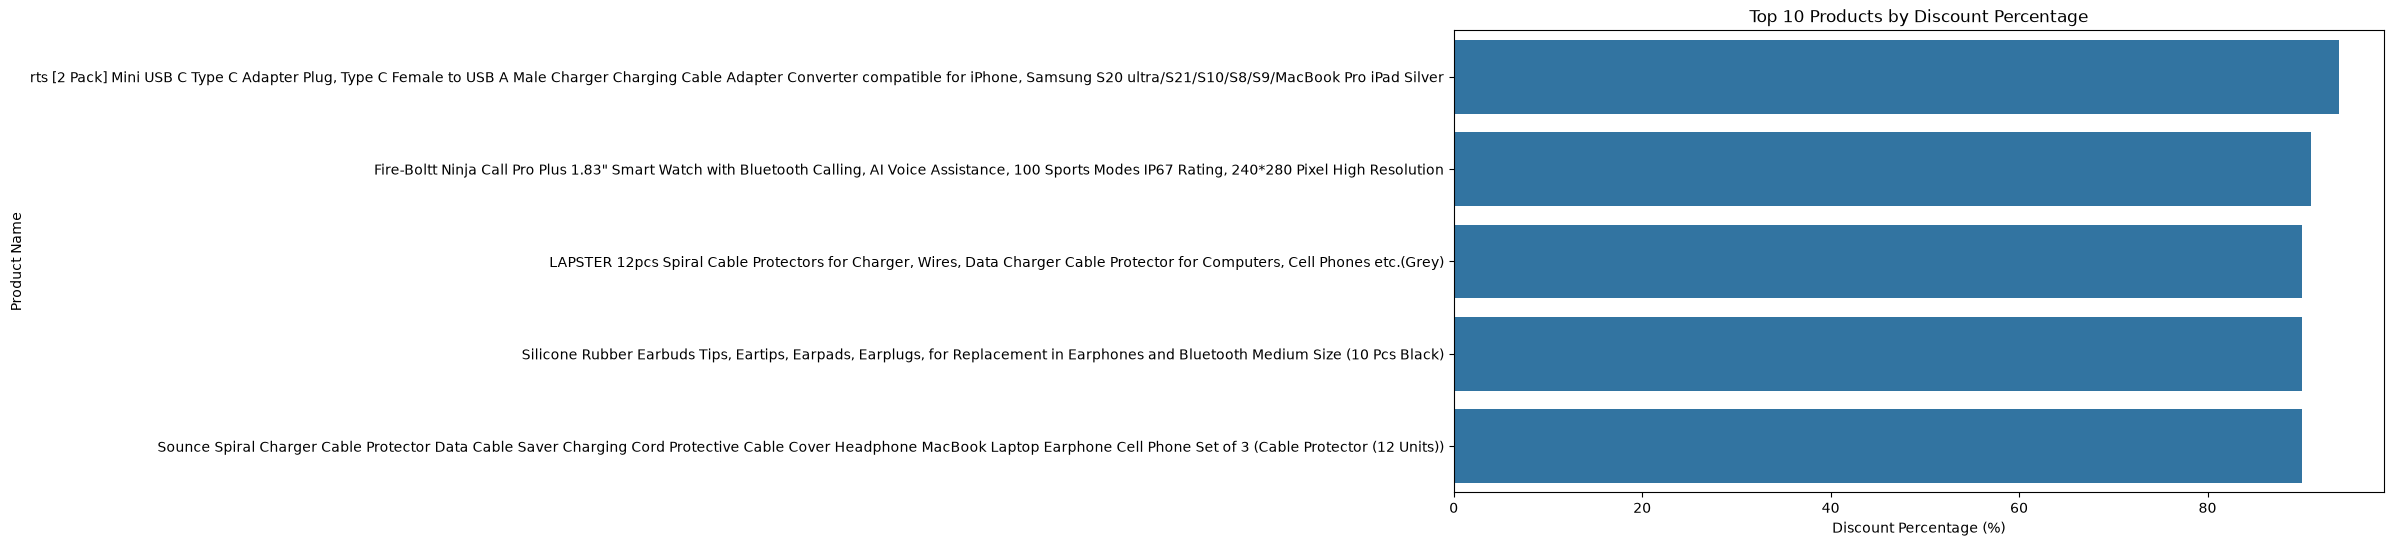

In [48]:
# Find the top 10 products by discount percentage
top_discount = (
    df.sort_values(by="discount_percentage", ascending=False)
    .head(10)
)

# Create the bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_discount,
    x="discount_percentage",
    y="product_name"
)

# Add chart title and labels
plt.title("Top 10 Products by Discount Percentage")
plt.xlabel("Discount Percentage (%)")
plt.ylabel("Product Name")

plt.tight_layout()
plt.show()

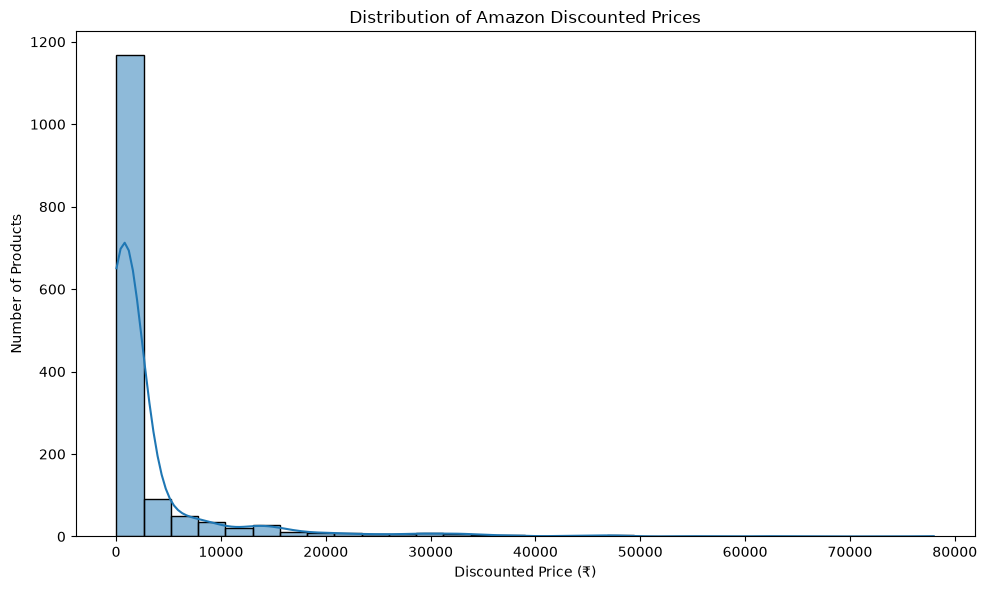

In [49]:
# Create a histogram of discounted prices
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x="discounted_price", bins=30, kde=True)

# Add chart title and labels
plt.title("Distribution of Amazon Discounted Prices")
plt.xlabel("Discounted Price (₹)")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()

In [51]:
#connect sqlite database connection
conn = sqlite3.connect("amazon_analysis.db")
#save the cleaned dataframe into a sql table
df.to_sql("amazon_products",conn, if_exists= "replace", index= False)
print("Data successfully saved to sqlite database!")

Data successfully saved to sqlite database!


In [52]:
query = "SELECT* FROM amazon_products LIMIT 5"
result = pd.read_sql_query(query, conn)
display(result)

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64.0,4.2,24269.0,High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,199.0,349.0,43.0,4.0,43994.0,"Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,199.0,1899.0,90.0,3.9,7928.0,【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,329.0,699.0,53.0,4.2,94363.0,The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,154.0,399.0,61.0,4.2,16905.0,[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [53]:
# Find the 10 products with the highest actual prices
query = """
SELECT product_name, actual_price, discounted_price, discount_percentage
FROM amazon_products
ORDER BY actual_price DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
display(result)

,product_name,actual_price,discounted_price,discount_percentage
0,Sony Bravia 164 cm (65 inches) 4K Ultra HD Sma...,139900.0,77990.0,44.0
1,VU 164 cm (65 inches) The GloLED Series 4K Sma...,85000.0,54990.0,35.0
2,LG 139 cm (55 inches) 4K Ultra HD Smart LED TV...,79990.0,47990.0,40.0
3,LG 1.5 Ton 5 Star AI DUAL Inverter Split AC (C...,75990.0,42990.0,43.0
4,"Samsung Galaxy S20 FE 5G (Cloud Navy, 8GB RAM,...",74999.0,37990.0,49.0
5,Samsung 138 cm (55 inches) Crystal 4K Neo Seri...,70900.0,47990.0,32.0
6,OnePlus 163.8 cm (65 inches) U Series 4K LED S...,69999.0,61999.0,11.0
7,MI 138.8 cm (55 inches) 5X Series 4K Ultra HD ...,69999.0,46999.0,33.0
8,Samsung 138 cm (55 inches) Crystal 4K Series U...,69900.0,45999.0,34.0
9,VU 139 cm (55 inches) The GloLED Series 4K Sma...,65000.0,37999.0,42.0


In [54]:
# Calculate average price and rating by category
query = """
SELECT
    category,
    COUNT(*) AS total_listings,
    ROUND(AVG(discounted_price), 2) AS avg_discounted_price,
    ROUND(AVG(rating), 2) AS avg_rating
FROM amazon_products
GROUP BY category
ORDER BY avg_discounted_price DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
display(result)

,category,total_listings,avg_discounted_price,avg_rating
0,"Home&Kitchen|Heating,Cooling&AirQuality|AirCon...",1,42990.00,4.30
1,Computers&Accessories|Laptops|TraditionalLaptops,1,37247.00,4.00
2,Computers&Accessories|Tablets,1,26999.00,4.60
3,"Electronics|HomeTheater,TV&Video|Televisions|S...",63,24840.19,4.21
4,"Home&Kitchen|Kitchen&HomeAppliances|Vacuum,Cle...",2,23449.50,4.25
5,Electronics|Mobiles&Accessories|Smartphones&Ba...,68,15754.44,4.10
6,Home&Kitchen|Kitchen&HomeAppliances|SmallKitch...,1,12609.00,4.40
7,"Home&Kitchen|Heating,Cooling&AirQuality|AirPur...",4,11917.00,4.28
8,Computers&Accessories|ExternalDevices&DataStor...,1,10389.00,4.40
9,"Electronics|HomeTheater,TV&Video|Projectors",3,9990.00,4.13


In [55]:
# Compare categories with at least 5 listings
query = """
SELECT
    category,
    COUNT(*) AS total_listings,
    ROUND(AVG(discounted_price), 2) AS avg_discounted_price,
    ROUND(AVG(rating), 2) AS avg_rating
FROM amazon_products
GROUP BY category
HAVING COUNT(*) >= 5
ORDER BY avg_rating DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
display(result)

,category,total_listings,avg_discounted_price,avg_rating
0,Electronics|Mobiles&Accessories|MobileAccessor...,7,577.71,4.47
1,Home&Kitchen|Kitchen&HomeAppliances|SmallKitch...,5,6276.40,4.46
2,Electronics|GeneralPurposeBatteries&BatteryCha...,7,327.43,4.41
3,Computers&Accessories|ExternalDevices&DataStor...,6,3516.83,4.40
4,Computers&Accessories|Accessories&Peripherals|...,6,943.67,4.38
5,Computers&Accessories|Accessories&Peripherals|...,8,368.63,4.38
6,OfficeProducts|OfficePaperProducts|Paper|Stati...,7,227.14,4.37
7,Electronics|Accessories|MemoryCards|MicroSD,13,839.77,4.33
8,Home&Kitchen|Kitchen&HomeAppliances|SmallKitch...,11,812.73,4.29
9,Computers&Accessories|Accessories&Peripherals|...,24,609.33,4.29


In [56]:
# Find the top 10 products with the highest discounts
query = """
SELECT
    product_name,
    actual_price,
    discounted_price,
    discount_percentage,
    rating
FROM amazon_products
ORDER BY discount_percentage DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
display(result)

,product_name,actual_price,discounted_price,discount_percentage,rating
0,"rts [2 Pack] Mini USB C Type C Adapter Plug, T...",4999.0,294.0,94.0,4.3
1,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",19999.0,1799.0,91.0,4.2
2,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",19999.0,1799.0,91.0,4.2
3,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",19999.0,1799.0,91.0,4.2
4,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",19999.0,1799.0,91.0,4.2
5,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",19999.0,1799.0,91.0,4.2
6,Sounce Fast Phone Charging Cable & Data Sync U...,1899.0,199.0,90.0,3.9
7,Sounce Spiral Charger Cable Protector Data Cab...,999.0,99.0,90.0,4.0
8,Sounce Protective Case Cover Compatible Boat X...,1899.0,199.0,90.0,4.0
9,LAPSTER 12pcs Spiral Cable Protectors for Char...,999.0,99.0,90.0,4.4


In [57]:
# Find highly rated products with at least 1,000 ratings
query = """
SELECT
    product_id,
    product_name,
    rating,
    rating_count,
    discounted_price
FROM amazon_products
WHERE rating >= 4.5
  AND rating_count >= 1000
ORDER BY rating DESC, rating_count DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
display(result)

,product_id,product_name,rating,rating_count,discounted_price
0,B0BR4F878Q,Swiffer Instant Electric Water Heater Faucet T...,4.8,53803.0,1439.0
1,B0B53DS4TF,"Instant Pot Air Fryer, Vortex 2QT, Touch Contr...",4.8,3964.0,4995.0
2,B0B23LW7NV,Spigen EZ Fit Tempered Glass Screen Protector ...,4.7,7779.0,999.0
3,B09WN3SRC7,Sony Bravia 164 cm (65 inches) 4K Ultra HD Sma...,4.7,5935.0,77990.0
4,B0BP89YBC1,Campfire Spring Chef Prolix Instant Portable W...,4.7,2591.0,1499.0
5,B0BM9H2NY9,Multifunctional 2 in 1 Electric Egg Boiling St...,4.7,2300.0,699.0
6,B0BM4KTNL1,"FIGMENT Handheld Milk Frother Rechargeable, 3-...",4.7,1729.0,699.0
7,B01J1CFO5I,Redgear MP35 Speed-Type Gaming Mousepad (Black...,4.6,33434.0,299.0
8,B095RTJH1M,Spigen EZ Fit Tempered Glass Screen Protector ...,4.6,26603.0,999.0
9,B01MQ2A86A,"Logitech M331 Silent Plus Wireless Mouse, 2.4G...",4.6,12375.0,1295.0


In [58]:
# Generate an overall summary of Amazon product listings
query = """
SELECT
    COUNT(*) AS total_listings,
    COUNT(DISTINCT product_id) AS unique_products,
    ROUND(AVG(actual_price), 2) AS avg_actual_price,
    ROUND(AVG(discounted_price), 2) AS avg_discounted_price,
    ROUND(AVG(discount_percentage), 2) AS avg_discount_percentage,
    ROUND(AVG(rating), 2) AS avg_rating
FROM amazon_products;
"""

result = pd.read_sql_query(query, conn)
display(result)

,total_listings,unique_products,avg_actual_price,avg_discounted_price,avg_discount_percentage,avg_rating
0,1465,1351,5444.99,3125.31,47.69,4.1


In [59]:
# Check repeated product IDs
print("Total rows:", len(df))
print("Unique product IDs:", df["product_id"].nunique())
print("Repeated product ID rows:", df["product_id"].duplicated().sum())
print("Number of product IDs repeated:", df.loc[
    df["product_id"].duplicated(keep=False), "product_id"
].nunique())

Total rows: 1465
Unique product IDs: 1351
Repeated product ID rows: 114
Number of product IDs repeated: 92
